In [8]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, GRU, LSTM, Input, Dense
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import  mean_squared_error

In [9]:
df = pd.read_csv("airline-passengers.csv");

In [10]:
df.head()

,Month,Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


In [15]:
pd_series = df.iloc[:,1].values.astype("float32").reshape(-1,1)

Text(0, 0.5, 'Passengers (thousands)')

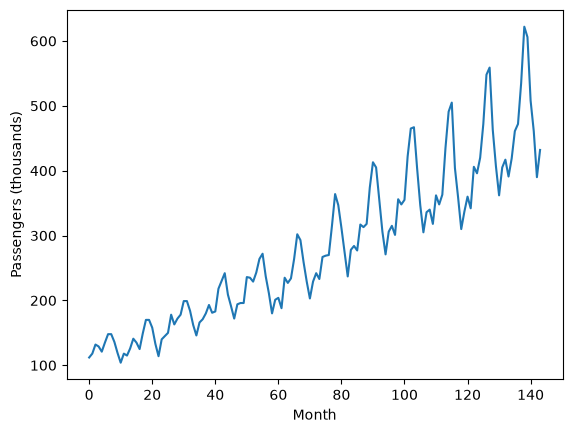

In [18]:
plt.plot(pd_series)
plt.xlabel("Month")
plt.ylabel("Passengers (thousands)")

In [19]:
split = int(len(pd_series)*0.8)
train_series = pd_series[:split]
test_series = pd_series[split:]

In [22]:
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_series)
test_scaled = scaler.transform(test_series)
print(train_scaled.shape)
print(test_scaled.shape)

(115, 1)
(29, 1)


In [29]:
LOOP_BACK = 12
def build_dataset(data, LOOP_BACK = 1):
    X, y = [], []
    for i in range(len(data) - LOOP_BACK):
        X.append(data[i:i+LOOP_BACK,0])
        y.append(data[i+LOOP_BACK,0])
    return np.array(X),np.array(y)

X_train, y_train = build_dataset(train_scaled,LOOP_BACK)
overlapped_test = np.vstack([train_scaled[-LOOP_BACK:],test_scaled])
X_test, y_test = build_dataset(overlapped_test,LOOP_BACK)

X_train = X_train.reshape(X_train.shape[0],LOOP_BACK,1)
X_test = X_test.reshape(X_test.shape[0],LOOP_BACK,1)

In [38]:
def train_and_eval(name,model,epochs=100):
    model.compile(optimizer = 'adam',loss = 'MSE')
    history = model.fit(
        X_train,y_train,
        validation_data = (X_test,y_test),
        epochs = epochs, batch_size = 8, verbose = 0
    )

    train_pred = model.predict(X_train,verbose = 0)
    test_pred = model.predict(X_test,verbose = 0)

    train_rmse = np.sqrt(mean_squared_error(y_train,train_pred)) 
    test_rmse = np.sqrt(mean_squared_error(y_test,test_pred))

    print(f"{name}\n | Train_rmse = {train_rmse} | Test_rmse = {test_rmse} |")

    plt.figure(figsize = (6,4))
    plt.plot(history.history['loss'],label = 'loss')
    plt.plot(history.history['val_loss'], label = 'val loss')
    plt.xlabel('epochs')
    plt.ylabel('RMSE')
    plt.legend()
    plt.show()

    return test_pred, y_test, test_rmse

RNN
 | Train_rmse = 0.030202693535206517 | Test_rmse = 0.07483856303153905 |


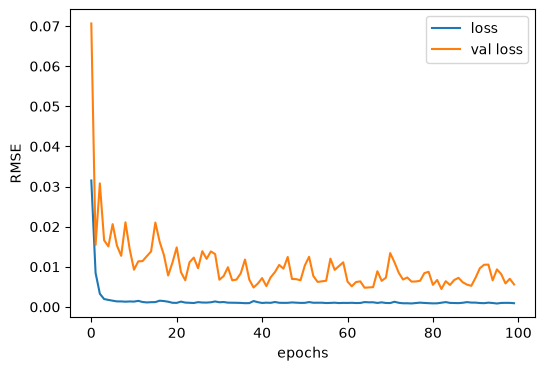

GRU
 | Train_rmse = 0.05118589391214819 | Test_rmse = 0.11522569866168278 |


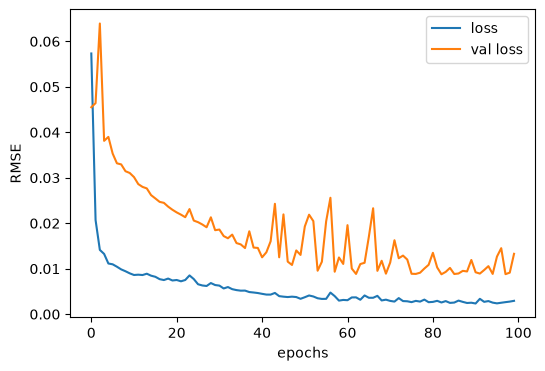

LSTM
 | Train_rmse = 0.05472501464291238 | Test_rmse = 0.16591672195226564 |


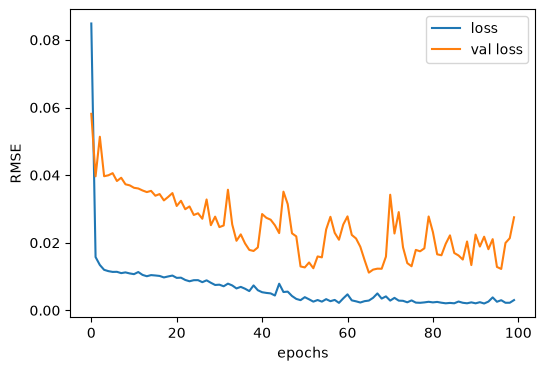

In [39]:
RNN = Sequential ([
    Input(shape=(LOOP_BACK,1)),
    SimpleRNN(50,activation = 'tanh'),
    Dense(1)
])

RNN_pred, _ , RNN_rmse = train_and_eval('RNN',RNN)

GRU = Sequential ([
    Input(shape = (LOOP_BACK,1)),
    GRU(50,activation = 'tanh'),
    Dense(1)
])

GRU_pred, _ , GRU_rmse = train_and_eval('GRU',GRU)

LSTM = Sequential ([
    Input(shape = (LOOP_BACK,1)),
    LSTM(50,activation = 'tanh'),
    Dense(1)
])

LSTM_pred, _ , LSTM_rmse = train_and_eval('LSTM',LSTM)

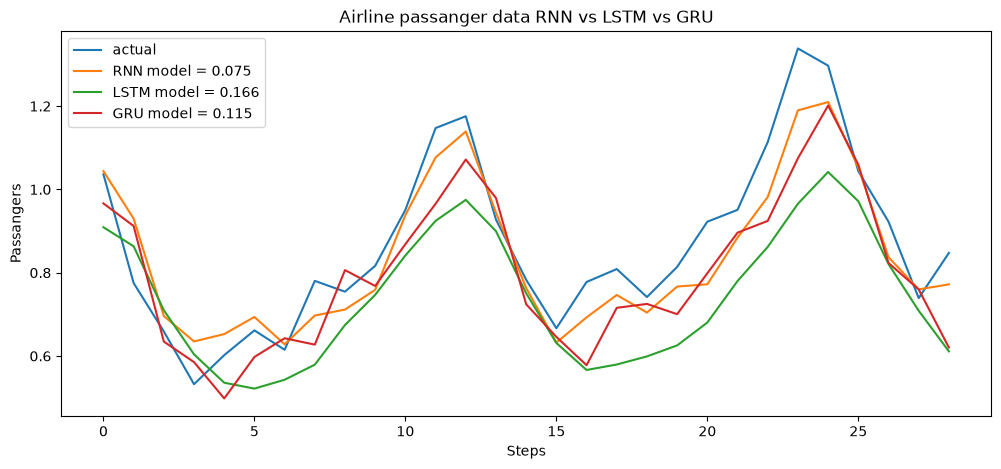

In [46]:
plt.figure(figsize=(12,5))
plt.title("Airline passanger data RNN vs LSTM vs GRU")
plt.plot(y_test,label = 'actual')
plt.plot(RNN_pred,label = f"RNN model = {RNN_rmse:.3f}")
plt.plot(LSTM_pred,label = f"LSTM model = {LSTM_rmse:.3f}")
plt.plot(GRU_pred,label = f"GRU model = {GRU_rmse:.3f}")
plt.xlabel("Steps")
plt.ylabel("Passangers")
plt.legend()
plt.show()